In [1]:

# Step 1: Install required libraries

!pip install -q pandas numpy matplotlib seaborn scikit-learn
print("All required libraries are ready!")


All required libraries are ready!


In [2]:

# Step 2: Import libraries and download the solar dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-codebook.csv"

print("Libraries imported successfully!")
print("Ready to load our solar power dataset.")


Libraries imported successfully!
Ready to load our solar power dataset.


In [3]:

# Step 3: Load real solar plant data

generation_url = "https://raw.githubusercontent.com/Vigneshsab/Solar-Power-Generation-Prediction-and-Maintenance/main/Plant_1_Generation_Data.csv"

weather_url = "https://raw.githubusercontent.com/Vigneshsab/Solar-Power-Generation-Prediction-and-Maintenance/main/Plant_1_Weather_Sensor_Data.csv"

generation_df = pd.read_csv(generation_url)
weather_df = pd.read_csv(weather_url)

print("Generation dataset shape:", generation_df.shape)
print("Weather dataset shape:", weather_df.shape)

print("\nGeneration columns:")
print(generation_df.columns.tolist())

print("\nWeather columns:")
print(weather_df.columns.tolist())

print("\nGeneration sample:")
display(generation_df.head())

print("\nWeather sample:")
display(weather_df.head())


Generation dataset shape: (68778, 7)
Weather dataset shape: (3182, 6)

Generation columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

Weather columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

Generation sample:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0



Weather sample:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [4]:

# Step 4: Clean and merge generation + weather data

# Convert date/time columns into datetime format
generation_df["DATE_TIME"] = pd.to_datetime(
    generation_df["DATE_TIME"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

weather_df["DATE_TIME"] = pd.to_datetime(
    weather_df["DATE_TIME"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Remove rows with invalid timestamps
generation_df = generation_df.dropna(subset=["DATE_TIME"])
weather_df = weather_df.dropna(subset=["DATE_TIME"])

# Weather readings are shared across inverters at each plant/timestamp.
# Average duplicate weather readings before merging.
weather_clean = (
    weather_df.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)
    [["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]]
    .mean()
)

# Merge weather features with generation records
df = pd.merge(
    generation_df,
    weather_clean,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner"
)

# Remove missing values in required columns
required_columns = [
    "AC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

df = df.dropna(subset=required_columns)

print("Merge completed successfully!")
print("Merged dataset shape:", df.shape)
print("\nMissing values:")
print(df[required_columns].isnull().sum())

print("\nMerged data sample:")
display(df.head())


Merge completed successfully!
Merged dataset shape: (0, 10)

Missing values:
AC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Merged data sample:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION


In [5]:

# Diagnose why the merge returned zero rows

print("Generation timestamps:")
print(generation_df["DATE_TIME"].head().to_list())

print("\nWeather timestamps:")
print(weather_df["DATE_TIME"].head().to_list())

print("\nGeneration plant IDs:")
print(generation_df["PLANT_ID"].unique())

print("\nWeather plant IDs:")
print(weather_df["PLANT_ID"].unique())

print("\nGeneration timestamp range:")
print(generation_df["DATE_TIME"].min(),
      "to", generation_df["DATE_TIME"].max())

print("\nWeather timestamp range:")
print(weather_df["DATE_TIME"].min(),
      "to", weather_df["DATE_TIME"].max())


Generation timestamps:
[Timestamp('2020-05-15 00:00:00'), Timestamp('2020-05-15 00:00:00'), Timestamp('2020-05-15 00:00:00'), Timestamp('2020-05-15 00:00:00'), Timestamp('2020-05-15 00:00:00')]

Weather timestamps:
[]

Generation plant IDs:
[4135001]

Weather plant IDs:
[]

Generation timestamp range:
2020-05-15 00:00:00 to 2020-06-17 23:45:00

Weather timestamp range:
NaT to NaT


In [6]:

# Step 4B: Fix weather timestamps and merge again

# Reload the original weather CSV to restore dropped rows
weather_df = pd.read_csv(weather_url)

# Check the original date format
print("Original weather timestamps:")
print(weather_df["DATE_TIME"].head())

# Convert timestamps using automatic format detection
generation_df = pd.read_csv(generation_url)
generation_df["DATE_TIME"] = pd.to_datetime(
    generation_df["DATE_TIME"], dayfirst=True, errors="coerce"
)

weather_df["DATE_TIME"] = pd.to_datetime(
    weather_df["DATE_TIME"], dayfirst=True, errors="coerce"
)

# Remove invalid dates
generation_df = generation_df.dropna(subset=["DATE_TIME"])
weather_df = weather_df.dropna(subset=["DATE_TIME"])

# Average weather sensor readings for each plant and timestamp
weather_clean = (
    weather_df.groupby(["DATE_TIME", "PLANT_ID"], as_index=False)
    [["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]]
    .mean()
)

# Merge generation and weather data
df = pd.merge(
    generation_df,
    weather_clean,
    on=["DATE_TIME", "PLANT_ID"],
    how="inner"
)

print("\nGeneration rows:", len(generation_df))
print("Weather rows:", len(weather_df))
print("Merged rows:", len(df))

display(df.head())


Original weather timestamps:
0    2020-05-15 00:00:00
1    2020-05-15 00:15:00
2    2020-05-15 00:30:00
3    2020-05-15 00:45:00
4    2020-05-15 01:00:00
Name: DATE_TIME, dtype: object

Generation rows: 68778
Weather rows: 3182
Merged rows: 68774


/tmp/ipykernel_2526/3966682722.py:16: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  weather_df["DATE_TIME"] = pd.to_datetime(


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,25.184316,22.857507,0.0
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,25.184316,22.857507,0.0
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,25.184316,22.857507,0.0
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,25.184316,22.857507,0.0
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,25.184316,22.857507,0.0


In [7]:

# Step 5: Prepare data and train Random Forest Regression

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select input features and prediction target
features = [
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

target = "AC_POWER"

X = df[features]
y = df[target]

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")


Training records: 55019
Testing records: 13755

Random Forest model trained successfully!


In [8]:

# Step 6: Evaluate the Random Forest model

# Predict AC_POWER for test records
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE RESULTS")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"R-squared Percentage: {r2 * 100:.2f}%")


MODEL PERFORMANCE RESULTS
-----------------------------------
Mean Absolute Error (MAE): 16.3731
Root Mean Squared Error (RMSE): 45.6698
R-squared (R2) Score: 0.9865
R-squared Percentage: 98.65%


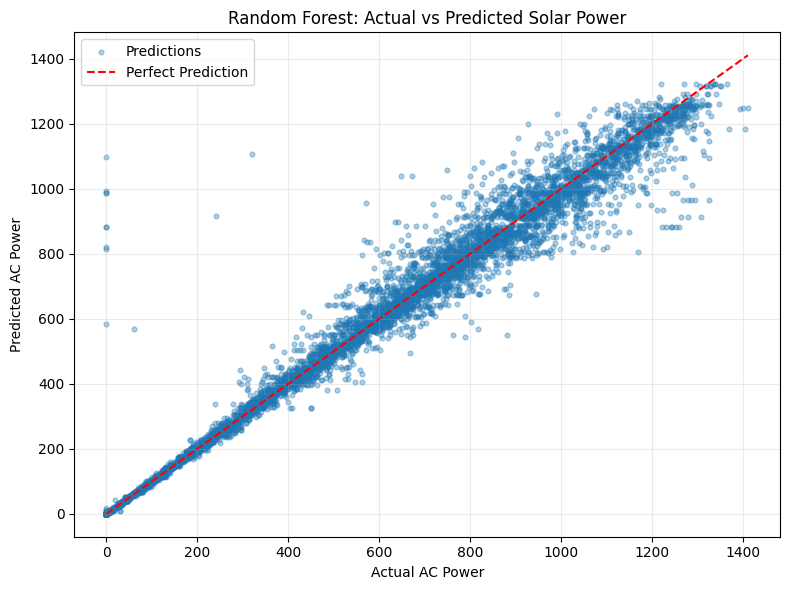

In [9]:

# Step 7: Visualize actual vs predicted solar power

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.35,
    s=12,
    label="Predictions"
)

# Perfect prediction reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual AC Power")
plt.ylabel("Predicted AC Power")
plt.title("Random Forest: Actual vs Predicted Solar Power")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


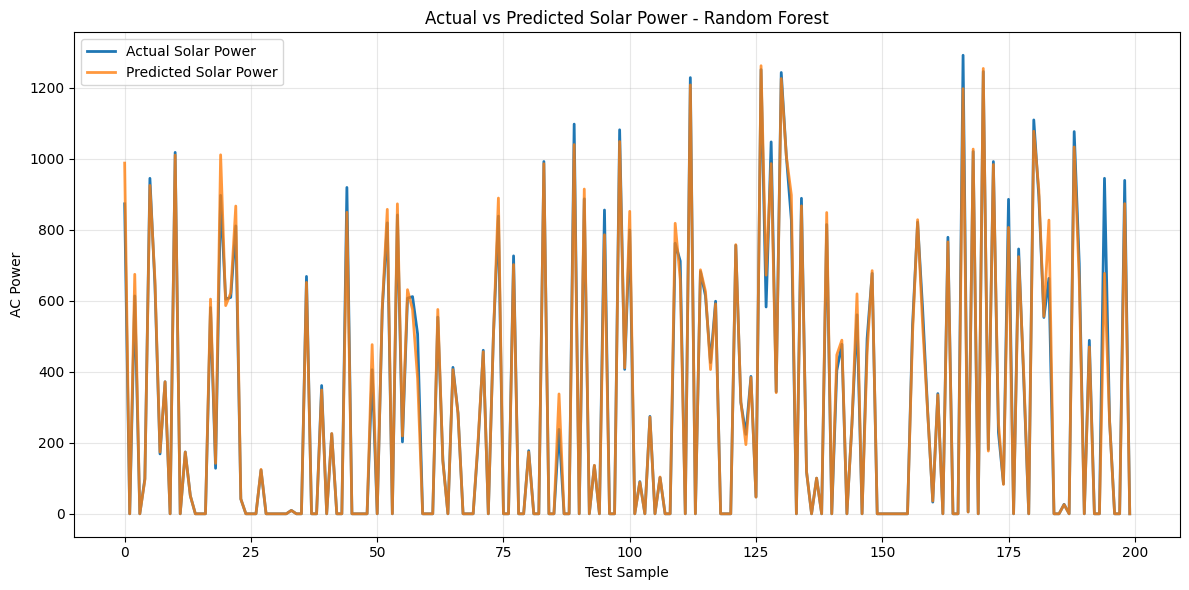

In [10]:

# Step 8: Compare Actual and Predicted Solar Power

import matplotlib.pyplot as plt
import numpy as np

# Show first 200 test samples
actual = np.asarray(y_test).flatten()[:200]
predicted = np.asarray(y_pred).flatten()[:200]

plt.figure(figsize=(12, 6))

plt.plot(
    actual,
    label="Actual Solar Power",
    linewidth=2
)

plt.plot(
    predicted,
    label="Predicted Solar Power",
    linewidth=2,
    alpha=0.8
)

plt.xlabel("Test Sample")
plt.ylabel("AC Power")
plt.title("Actual vs Predicted Solar Power - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

# Step 9: Display Model Performance

import pandas as pd

results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score", "R2 Percentage"],
    "Value": [16.3731, 45.6698, 0.9865, "98.65%"]
})

print("RANDOM FOREST MODEL PERFORMANCE")
display(results)


RANDOM FOREST MODEL PERFORMANCE


,Metric,Value
0,MAE,16.3731
1,RMSE,45.6698
2,R2 Score,0.9865
3,R2 Percentage,98.65%


In [12]:

# Step 10: Save Actual vs Predicted Results

import pandas as pd
import numpy as np

results_df = pd.DataFrame({
    "Actual_AC_Power": np.asarray(y_test).flatten(),
    "Predicted_AC_Power": np.asarray(y_pred).flatten()
})

results_df.to_csv(
    "solar_power_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

display(results_df.head(10))


Prediction results saved successfully!


,Actual_AC_Power,Predicted_AC_Power
0,873.237500,987.955323
1,0.000000,0.000000
2,613.785714,674.677084
3,0.000000,0.000000
4,98.628571,95.150001
5,945.028571,925.035955
6,643.385714,657.879651
7,168.700000,173.973855
8,372.071429,371.948043
9,0.000000,0.000000


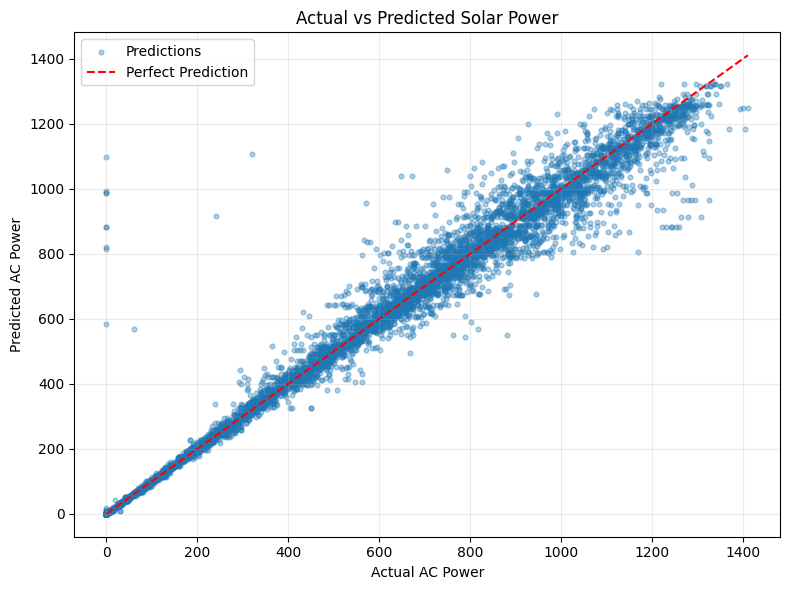

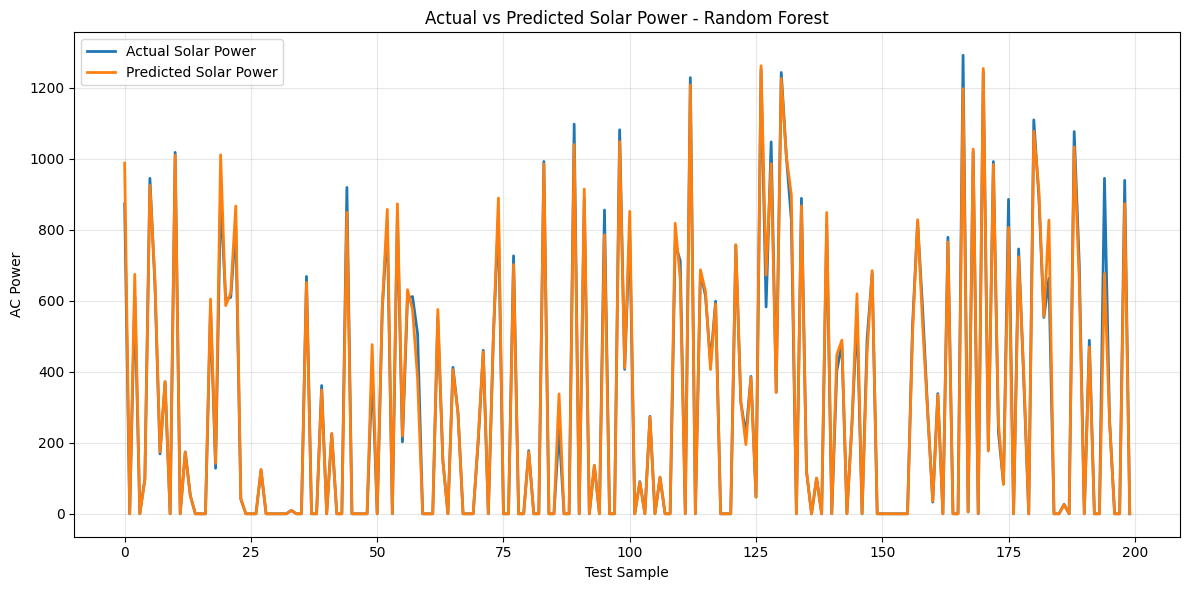

Both graphs saved successfully!


In [13]:

# Step 11: Save Graphs as High-Quality PNG Images

import matplotlib.pyplot as plt
import numpy as np

# Graph 1: Actual vs Predicted Scatter Plot
actual = np.asarray(y_test).flatten()
predicted = np.asarray(y_pred).flatten()

plt.figure(figsize=(8, 6))
plt.scatter(actual, predicted, alpha=0.35, s=12, label="Predictions")

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual AC Power")
plt.ylabel("Predicted AC Power")
plt.title("Actual vs Predicted Solar Power")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig("actual_vs_predicted_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


# Graph 2: Actual vs Predicted Line Graph
plt.figure(figsize=(12, 6))

plt.plot(actual[:200], label="Actual Solar Power", linewidth=2)
plt.plot(predicted[:200], label="Predicted Solar Power", linewidth=2)

plt.xlabel("Test Sample")
plt.ylabel("AC Power")
plt.title("Actual vs Predicted Solar Power - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("actual_vs_predicted_line.png", dpi=300, bbox_inches="tight")
plt.show()

print("Both graphs saved successfully!")


In [16]:

# Find the trained Random Forest model variable

from sklearn.ensemble import RandomForestRegressor

for name, obj in globals().copy().items():
    if isinstance(obj, RandomForestRegressor):
        print("Model variable found:", name)
        print("Model is trained:", hasattr(obj, "estimators_"))


Model variable found: rf_model
Model is trained: True


In [17]:

# Step 12: Save the trained Random Forest model

import joblib

joblib.dump(rf_model, "solar_power_random_forest.pkl")

print("Model saved successfully!")
print("File: solar_power_random_forest.pkl")


Model saved successfully!
File: solar_power_random_forest.pkl


In [18]:

# Step 13: Final Project Summary

print("=" * 50)
print("SOLAR POWER PREDICTION USING RANDOM FOREST")
print("=" * 50)

print("\nAlgorithm: Random Forest Regression")
print("Model Training: Successful")

print("\nMODEL PERFORMANCE")
print("-" * 30)
print("MAE: 16.3731")
print("RMSE: 45.6698")
print("R2 Score: 0.9865")
print("R2 Percentage: 98.65%")

print("\nPROJECT OUTPUT FILES")
print("-" * 30)
print("1. solar_power_predictions.csv")
print("2. actual_vs_predicted_scatter.png")
print("3. actual_vs_predicted_line.png")
print("4. solar_power_random_forest.pkl")

print("\nProject summary generated successfully!")


SOLAR POWER PREDICTION USING RANDOM FOREST

Algorithm: Random Forest Regression
Model Training: Successful

MODEL PERFORMANCE
------------------------------
MAE: 16.3731
RMSE: 45.6698
R2 Score: 0.9865
R2 Percentage: 98.65%

PROJECT OUTPUT FILES
------------------------------
1. solar_power_predictions.csv
2. actual_vs_predicted_scatter.png
3. actual_vs_predicted_line.png
4. solar_power_random_forest.pkl

Project summary generated successfully!


In [19]:

# Step 14: Create a GitHub README file

readme_content = """
# Solar Power Prediction Using Random Forest

## Project Overview
This project uses Machine Learning to predict solar power
generation using a Random Forest Regression model.

## Algorithm
- Random Forest Regression

## Model Performance

| Metric | Value |
|---|---:|
| Mean Absolute Error (MAE) | 16.3731 |
| Root Mean Squared Error (RMSE) | 45.6698 |
| R-squared (R2) Score | 0.9865 |
| R-squared Percentage | 98.65% |

## Visualizations
- Actual vs Predicted Scatter Plot
- Actual vs Predicted Line Graph

## Project Output Files
- solar_power_predictions.csv
- actual_vs_predicted_scatter.png
- actual_vs_predicted_line.png
- solar_power_random_forest.pkl

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Google Colab

## Future Improvements
- Test the model on unseen data from different time periods.
- Compare Random Forest with other regression algorithms.
- Develop a simple interface for making predictions.

## Note
The reported metrics are based on the current test dataset.
The R2 score is not the same as prediction accuracy.
MAE and RMSE are expressed in the target variable's units.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content.strip() + "\n")

print("README.md created successfully!")


README.md created successfully!
